In [1]:

from google.colab import files
uploaded = files.upload()


Saving india_regional_market_v2.csv to india_regional_market_v2.csv


In [2]:

import pandas as pd
import os

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape: (400, 11)

Column Names:
['RegionID', 'City', 'State', 'Latitude', 'Longitude', 'PopulationSegment', 'MonthlySearchDemand', 'ExistingCompetitors', 'MedianAnnualIncomeINR', 'LeadConversionRate', 'EstimatedAcquisitionCostINR']

Missing Values:
RegionID                       0
City                           0
State                          0
Latitude                       0
Longitude                      0
PopulationSegment              0
MonthlySearchDemand            0
ExistingCompetitors            0
MedianAnnualIncomeINR          0
LeadConversionRate             0
EstimatedAcquisitionCostINR    0
dtype: int64

First 5 Rows:


,RegionID,City,State,Latitude,Longitude,PopulationSegment,MonthlySearchDemand,ExistingCompetitors,MedianAnnualIncomeINR,LeadConversionRate,EstimatedAcquisitionCostINR
0,REG-0001,Delhi,Delhi,28.65506,77.14308,Student,1071,9,812870,0.1116,618
1,REG-0002,Hyderabad,Telangana,17.45908,78.36344,Student,654,15,938393,0.1228,748
2,REG-0003,Delhi,Delhi,28.56055,77.13678,Professional,574,10,445873,0.1191,634
3,REG-0004,Kolkata,West Bengal,22.70194,88.38826,Professional,389,4,802466,0.0308,330
4,REG-0005,Pune,Maharashtra,18.58053,73.76657,Student,538,11,370930,0.0974,150


In [3]:

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head(10))


Dataset Shape: (400, 11)
Columns: ['RegionID', 'City', 'State', 'Latitude', 'Longitude', 'PopulationSegment', 'MonthlySearchDemand', 'ExistingCompetitors', 'MedianAnnualIncomeINR', 'LeadConversionRate', 'EstimatedAcquisitionCostINR']


,RegionID,City,State,Latitude,Longitude,PopulationSegment,MonthlySearchDemand,ExistingCompetitors,MedianAnnualIncomeINR,LeadConversionRate,EstimatedAcquisitionCostINR
0,REG-0001,Delhi,Delhi,28.65506,77.14308,Student,1071,9,812870,0.1116,618
1,REG-0002,Hyderabad,Telangana,17.45908,78.36344,Student,654,15,938393,0.1228,748
2,REG-0003,Delhi,Delhi,28.56055,77.13678,Professional,574,10,445873,0.1191,634
3,REG-0004,Kolkata,West Bengal,22.70194,88.38826,Professional,389,4,802466,0.0308,330
4,REG-0005,Pune,Maharashtra,18.58053,73.76657,Student,538,11,370930,0.0974,150
5,REG-0006,Delhi,Delhi,28.76618,77.27371,Early Career,658,1,824934,0.0926,191
6,REG-0007,Delhi,Delhi,28.76743,77.30769,Early Career,938,15,733993,0.1369,258
7,REG-0008,Jaipur,Rajasthan,26.79367,75.92059,Professional,1529,11,512659,0.0401,503
8,REG-0009,Ahmedabad,Gujarat,22.97992,72.42768,Professional,645,14,523812,0.1113,611
9,REG-0010,Delhi,Delhi,28.62477,77.06437,Early Career,568,13,905667,0.0736,776


In [4]:

import pandas as pd
import matplotlib.pyplot as plt

# Clean the regional dataset
df.columns = df.columns.str.strip()

df["City"] = df["City"].astype(str).str.strip()
df["State"] = df["State"].astype(str).str.strip()

numeric_cols = [
    "Latitude", "Longitude", "MonthlySearchDemand",
    "ExistingCompetitors", "MedianAnnualIncomeINR",
    "LeadConversionRate", "EstimatedAcquisitionCostINR"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=[
    "City", "State", "Latitude", "Longitude",
    "MonthlySearchDemand", "ExistingCompetitors",
    "LeadConversionRate"
])

# Aggregate regional metrics
regional = df.groupby(["State", "City"]).agg(
    Regions=("RegionID", "count"),
    SearchDemand=("MonthlySearchDemand", "sum"),
    Competitors=("ExistingCompetitors", "mean"),
    Avg_Conversion=("LeadConversionRate", "mean"),
    Avg_Income=("MedianAnnualIncomeINR", "mean"),
    Avg_Acquisition_Cost=("EstimatedAcquisitionCostINR", "mean"),
    Latitude=("Latitude", "mean"),
    Longitude=("Longitude", "mean")
).reset_index()

regional["Avg_Conversion"] *= 100

print("Cleaned Dataset Shape:", df.shape)
print("Unique Cities:", regional["City"].nunique())
print("\nTop 10 Cities by Search Demand:")
display(
    regional.sort_values("SearchDemand", ascending=False)
    .head(10).round(2)
)

print("\nRegional Summary:")
display(regional.describe().round(2))


Cleaned Dataset Shape: (400, 11)
Unique Cities: 10

Top 10 Cities by Search Demand:


,State,City,Regions,SearchDemand,Competitors,Avg_Conversion,Avg_Income,Avg_Acquisition_Cost,Latitude,Longitude
7,Tamil Nadu,Chennai,47,53771,7.94,7.88,678182.09,411.68,13.09,80.27
0,Delhi,Delhi,56,53007,8.02,7.27,701424.14,486.23,28.61,77.20
1,Gujarat,Ahmedabad,50,52110,8.38,8.40,710723.80,487.00,23.04,72.56
8,Telangana,Hyderabad,42,48103,7.19,8.15,665610.38,438.57,17.39,78.48
5,Maharashtra,Pune,41,44574,7.93,7.25,665734.78,479.20,18.53,73.84
3,Kerala,Kochi,39,39015,6.79,8.07,660594.08,520.38,9.92,76.26
6,Rajasthan,Jaipur,33,34849,7.67,7.98,668222.45,446.85,26.89,75.83
9,West Bengal,Kolkata,32,34126,8.56,7.26,649083.97,392.50,22.58,88.38
2,Karnataka,Bengaluru,32,33789,7.72,8.78,646762.56,476.34,12.99,77.57
4,Maharashtra,Mumbai,28,31275,7.18,8.54,661808.07,456.46,19.06,72.91



Regional Summary:


,Regions,SearchDemand,Competitors,Avg_Conversion,Avg_Income,Avg_Acquisition_Cost,Latitude,Longitude
count,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00
mean,40.00,42461.90,7.74,7.96,670814.63,459.52,19.21,77.33
std,9.02,8870.39,0.55,0.55,20762.88,38.34,6.14,4.60
min,28.00,31275.00,6.79,7.25,646762.56,392.50,9.92,72.56
25%,32.25,34306.75,7.31,7.42,660897.58,440.64,14.16,74.34
50%,40.00,41794.50,7.82,8.02,665672.58,466.40,18.80,76.73
75%,45.75,51108.25,8.00,8.34,675692.18,484.47,22.93,78.25
max,56.00,53771.00,8.56,8.78,710723.80,520.38,28.61,88.38


In [5]:

!pip -q install folium

import folium
from folium.plugins import MarkerCluster

# Center map around India
geo_map = folium.Map(
    location=[22.5, 79.0],
    zoom_start=5,
    tiles="CartoDB positron"
)

marker_cluster = MarkerCluster().add_to(geo_map)

for _, row in regional.iterrows():
    popup_text = f"""
    <b>City:</b> {row['City']}<br>
    <b>State:</b> {row['State']}<br>
    <b>Search Demand:</b> {row['SearchDemand']:.0f}<br>
    <b>Average Competitors:</b> {row['Competitors']:.1f}<br>
    <b>Lead Conversion:</b> {row['Avg_Conversion']:.2f}%<br>
    <b>Average Income:</b> ₹{row['Avg_Income']:,.0f}
    """

    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=max(4, min(14, row["SearchDemand"] / 200)),
        popup=folium.Popup(popup_text, max_width=300),
        tooltip=f"{row['City']} — Demand: {row['SearchDemand']:.0f}",
        color="blue",
        fill=True,
        fill_opacity=0.6
    ).add_to(marker_cluster)

map_file = "Geospatial_Regional_Analysis_Map.html"
geo_map.save(map_file)

print("Interactive map saved:", map_file)
display(geo_map)


Interactive map saved: Geospatial_Regional_Analysis_Map.html


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [6]:

!pip -q install folium

import folium
from folium.plugins import MarkerCluster

# Center map around India
geo_map = folium.Map(
    location=[22.5, 79.0],
    zoom_start=5,
    tiles="CartoDB positron"
)

marker_cluster = MarkerCluster().add_to(geo_map)

for _, row in regional.iterrows():
    popup_text = f"""
    <b>City:</b> {row['City']}<br>
    <b>State:</b> {row['State']}<br>
    <b>Search Demand:</b> {row['SearchDemand']:.0f}<br>
    <b>Average Competitors:</b> {row['Competitors']:.1f}<br>
    <b>Lead Conversion:</b> {row['Avg_Conversion']:.2f}%<br>
    <b>Average Income:</b> ₹{row['Avg_Income']:,.0f}
    """

    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=max(4, min(14, row["SearchDemand"] / 200)),
        popup=folium.Popup(popup_text, max_width=300),
        tooltip=f"{row['City']} — Demand: {row['SearchDemand']:.0f}",
        color="blue",
        fill=True,
        fill_opacity=0.6
    ).add_to(marker_cluster)

map_file = "Geospatial_Regional_Analysis_Map.html"
geo_map.save(map_file)

print("Interactive map saved:", map_file)
display(geo_map)


Interactive map saved: Geospatial_Regional_Analysis_Map.html


===== TOP 3 POTENTIAL EXPANSION REGIONS =====


,City,State,SearchDemand,Competitors,Avg_Conversion,Avg_Acquisition_Cost,Opportunity_Score
8,Hyderabad,Telangana,48103,7.19,8.15,438.57,72.47
7,Chennai,Tamil Nadu,53771,7.94,7.88,411.68,68.85
1,Ahmedabad,Gujarat,52110,8.38,8.40,487.00,64.45


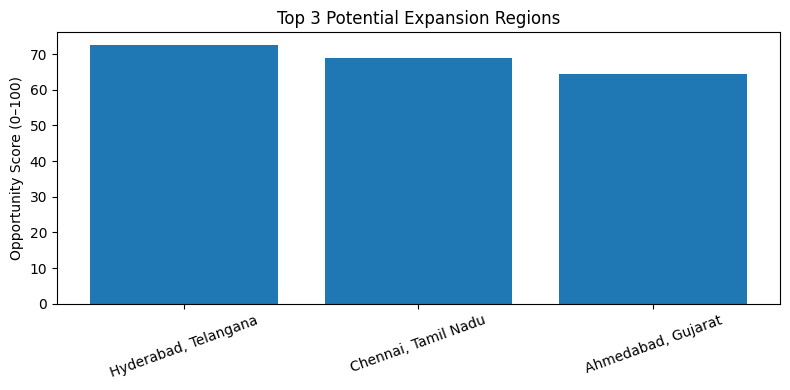

In [7]:

# Rank regions using demand, competition and conversion
ranked = regional.copy()

# Normalize values so they can be compared fairly
ranked["Demand_Score"] = (
    ranked["SearchDemand"] - ranked["SearchDemand"].min()
) / (ranked["SearchDemand"].max() - ranked["SearchDemand"].min() + 1e-9)

ranked["Competition_Score"] = (
    ranked["Competitors"].max() - ranked["Competitors"]
) / (ranked["Competitors"].max() - ranked["Competitors"].min() + 1e-9)

ranked["Conversion_Score"] = (
    ranked["Avg_Conversion"] - ranked["Avg_Conversion"].min()
) / (ranked["Avg_Conversion"].max() - ranked["Avg_Conversion"].min() + 1e-9)

# Combined opportunity score
ranked["Opportunity_Score"] = 100 * (
    0.50 * ranked["Demand_Score"]
    + 0.30 * ranked["Competition_Score"]
    + 0.20 * ranked["Conversion_Score"]
)

top3 = ranked.sort_values(
    "Opportunity_Score", ascending=False
).head(3)

print("===== TOP 3 POTENTIAL EXPANSION REGIONS =====")
display(top3[[
    "City", "State", "SearchDemand", "Competitors",
    "Avg_Conversion", "Avg_Acquisition_Cost",
    "Opportunity_Score"
]].round(2))

# Visualize the top 3
plt.figure(figsize=(8, 4))
plt.bar(
    top3["City"] + ", " + top3["State"],
    top3["Opportunity_Score"]
)
plt.title("Top 3 Potential Expansion Regions")
plt.ylabel("Opportunity Score (0–100)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [8]:

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import pandas as pd
import os

pdf_name = "Geospatial_Analysis_Report.pdf"

# Confirm previous analysis variables exist
assert "regional" in globals(), "Pehle regional analysis code run karo."
assert "top3" in globals(), "Pehle Top 3 regions wala code run karo."

with PdfPages(pdf_name) as pdf:

    # PAGE 1: Executive summary
    fig = plt.figure(figsize=(11.7, 8.3))
    fig.suptitle(
        "GEOSPATIAL DATA ANALYSIS REPORT",
        fontsize=20, fontweight="bold"
    )

    fig.text(0.08, 0.83, "Regional Market Expansion Analysis",
             fontsize=14, fontweight="bold")
    fig.text(0.08, 0.75, f"Regional records analyzed: {len(df):,}",
             fontsize=12)
    fig.text(0.08, 0.70, f"City-region combinations: {len(regional):,}",
             fontsize=12)

    fig.text(0.08, 0.60, "Top 3 Potential Expansion Regions",
             fontsize=14, fontweight="bold")

    y = 0.53
    for _, row in top3.iterrows():
        line = (
            f"{row['City']}, {row['State']} | "
            f"Demand: {row['SearchDemand']:.0f} | "
            f"Avg. competitors: {row['Competitors']:.1f} | "
            f"Conversion: {row['Avg_Conversion']:.2f}%"
        )
        fig.text(0.09, y, line, fontsize=10)
        y -= 0.08

    fig.text(
        0.08, 0.20,
        "Method: regions are ranked using a weighted score of search demand, "
        "lower competitor presence, and lead conversion.",
        fontsize=10, wrap=True
    )
    fig.text(
        0.08, 0.12,
        "Limitation: the dataset contains demand and market indicators, "
        "not verified sales revenue. Validate findings before investment.",
        fontsize=9, wrap=True
    )
    plt.axis("off")
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # PAGE 2: Search demand chart
    fig, ax = plt.subplots(figsize=(11.7, 8.3))
    demand_top = regional.sort_values(
        "SearchDemand", ascending=False
    ).head(10)

    ax.bar(
        demand_top["City"] + ", " + demand_top["State"],
        demand_top["SearchDemand"]
    )
    ax.set_title("Top 10 City-Regions by Monthly Search Demand")
    ax.set_ylabel("Monthly Search Demand")
    ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # PAGE 3: Top 3 opportunity scores
    fig, ax = plt.subplots(figsize=(11.7, 8.3))
    labels = top3["City"] + ", " + top3["State"]

    ax.bar(labels, top3["Opportunity_Score"])
    ax.set_title("Top 3 Potential Expansion Regions")
    ax.set_ylabel("Opportunity Score (0–100)")
    ax.tick_params(axis="x", rotation=20)
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # PAGE 4: Regional comparison table
    fig, ax = plt.subplots(figsize=(11.7, 8.3))
    ax.axis("off")
    ax.set_title("Regional Market Comparison",
                 fontsize=16, fontweight="bold", pad=20)

    table_df = regional[[
        "City", "State", "SearchDemand", "Competitors",
        "Avg_Conversion", "Avg_Acquisition_Cost"
    ]].sort_values("SearchDemand", ascending=False).head(15).round(2)

    table = ax.table(
        cellText=table_df.values,
        colLabels=table_df.columns,
        loc="center",
        cellLoc="center"
    )
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.4)

    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

print("Report created:", pdf_name)

from google.colab import files
files.download(pdf_name)


Report created: Geospatial_Analysis_Report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

import os
from google.colab import files

map_file = "Geospatial_Regional_Analysis_Map.html"

if os.path.exists(map_file):
    files.download(map_file)
else:
    print("Map file nahi mili. Map generation wala code dobara run karo.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>